# Clasificación de objetos astronómicos: galaxia, estrella o quásar

Trabajo Práctico

---
## Resumen del trabajo (hasta ahora)

**El objetivo del proyecto**

El punto de partida es un conjunto de datos astronómicos: cada fila es un objeto observado por un telescopio (galaxia, estrella o quásar), con mediciones de brillo en distintas bandas de luz y otras variables, entre ellas el "redshift" (corrimiento al rojo, una medida relacionada con qué tan lejos está el objeto y a qué velocidad se aleja).

La pregunta central del trabajo es:

**¿se puede predecir automáticamente si un objeto es galaxia, estrella o quásar a partir de estas mediciones, y cuánto de esa predicción depende únicamente del redshift?**

Esto último importa porque el redshift es una medida costosa de obtener con precisión, mientras que el brillo en distintas bandas es más fácil de medir. Si un modelo funciona casi igual de bien sin el redshift, eso tiene valor práctico.

**Qué se hizo hasta ahora**

1. **Carga y limpieza de datos.** Se revisó el archivo, se identificaron y eliminaron los valores sin medición (marcados como -9999) y los registros duplicados.

2. **Análisis exploratorio.** Se estudió el desbalance entre clases (hay muchas más galaxias que quásares), se calcularon correlaciones entre variables, y se crearon los "colores fotométricos" (diferencias entre bandas de brillo consecutivas), que resultaron menos redundantes entre sí que las bandas originales. También se revisaron valores atípicos por clase.

3. **Preparación de los datos para el modelado.** Se dividió el conjunto en entrenamiento y prueba de forma proporcional a cada clase, se corrigió el desbalance solo en el conjunto de entrenamiento (duplicando registros de las clases minoritarias), y se normalizó la escala de las variables. Se armaron dos versiones de los datos: una con el redshift incluido y otra sin él, para poder comparar.

4. **Entrenamiento y comparación de cuatro modelos distintos**, cada uno en sus dos versiones (con y sin redshift):
   - **KNN**, un modelo simple que clasifica por cercanía a otros casos conocidos, usado como punto de referencia inicial.
   - **SVM**, que busca la frontera óptima entre clases.
   - **Árbol de decisión**, un modelo que toma decisiones mediante reglas simples y es fácil de interpretar visualmente.
   - **Random Forest**, un conjunto de muchos árboles combinados, generalmente más robusto que uno solo.

   Para cada modelo se buscaron los mejores parámetros mediante validación cruzada, y se evaluó el resultado final sobre el conjunto de prueba (que nunca participó del ajuste, para que la medición fuera honesta).

5. **Importancia de atributos.** Con el mejor modelo (Random Forest), se midió qué variables pesan más en la predicción, usando dos métodos distintos que terminaron coincidiendo en sus conclusiones principales.

**Hasta dónde se llegó**

El trabajo está completo hasta el punto que se había planificado: preparación de datos, cuatro modelos comparados en sus dos versiones, y análisis de importancia de variables.

Los resultados respondieron la pregunta original con bastante claridad: con el redshift incluido, el mejor modelo (Random Forest) clasifica correctamente casi todos los casos, y esa variable concentra más de la mitad de la importancia total. Sin el redshift, la tarea sigue siendo posible pero notablemente más difícil, y la variable que más ayuda a compensar su ausencia es una de las diferencias de color entre bandas (r menos i), la misma que resultó ser la primera pregunta que hace el árbol de decisión al clasificar un objeto.

Lo que queda pendiente, según la hoja de ruta del propio cuaderno, es la etapa siguiente que aún no se abordó (marcada como pasos futuros en la notebook), pero todo lo planificado hasta ensambles e importancia de atributos está resuelto y documentado.

---

## Fuente de los datos

Los datos provienen del **Sloan Digital Sky Survey, Data Release 17 (SDSS DR17)**, obtenidos del
[SkyServer](https://skyserver.sdss.org/dr17/SearchTools/sql) mediante la siguiente consulta SQL,
ejecutada el 3 de septiembre de 2026:

```sql
SELECT TOP 100000
  p.objid, p.ra, p.dec, p.u, p.g, p.r, p.i, p.z,
  s.class, s.z AS redshift
FROM PhotoObj AS p
JOIN SpecObj AS s ON s.bestobjid = p.objid
WHERE s.scienceprimary = 1
ORDER BY p.objid
```

Se tomaron los datos del relevamiento original y no de una copia intermedia, de modo que la fuente sea
verificable: cualquier lector puede ejecutar la misma consulta y obtener la misma tabla. El
`ORDER BY p.objid` es necesario para eso: sin él, `SELECT TOP` devuelve una muestra distinta en cada
ejecución. Con él, dos descargas independientes producen un archivo idéntico
(MD5 `767f1802fbe4fa9d961372c54ca0cf7c`).

PhotoObj = Informacion fotometrica
SpecObj = Informacion espectroscópica
scienceprimary = 1 Selecciona el espectro considerado primario para análisis científico, ayudando a evitar observaciones espectroscópicas repetidas del mismo objeto

El motivo habitual para hacer esto es la calidad de la fotometría. Al acercarte al límite de detección del survey, aumenta la incertidumbre de las magnitudes. Eso afecta especialmente a u, que suele ser una banda más ruidosa; de ahí que pueda usarse un corte más restrictivo como u < 19.6.

El archivo resultante, `data/Skyserver_nofilter.csv`, acompaña a esta notebook.
El archivo `sdss17_skyserver.csv` se puede usar tambien y contiene informacion filtrando por rango de u BETWEEN 0 AND 19.6
  y g BETWEEN 0 AND 20

## Propuesta de investigación

Cada fila del conjunto de datos es un objeto celeste observado, y la tarea consiste en clasificarlo en
**galaxia**, **estrella** o **quásar**. Las variables disponibles son de dos naturalezas distintas: la
**fotometría** en cinco filtros (`u`, `g`, `r`, `i`, `z`), que mide el brillo del objeto en distintas bandas
del espectro, y el **corrimiento al rojo** (`redshift`), que mide cuánto se estiró la longitud de onda de su
luz por la expansión del universo y funciona, por lo tanto, como un indicador de distancia.

Esa diferencia de naturaleza es el punto de partida del trabajo. Una estrella pertenece a nuestra propia
galaxia y no se aleja, de modo que su corrimiento al rojo es prácticamente nulo; una galaxia está lejos y
presenta un corrimiento moderado; un quásar es el núcleo activo de una galaxia muy distante y presenta un
corrimiento alto. En consecuencia, cabe esperar que el `redshift` por sí solo permita separar las tres
clases casi por completo, lo que volvería trivial cualquier modelo que lo utilice.

**La pregunta que guía este trabajo es cuánto de la clasificación se explica únicamente con el
`redshift`, y qué ocurre cuando esa variable no está disponible.** La segunda situación no es hipotética:
obtener el corrimiento al rojo requiere un espectro, que es una observación costosa, mientras que la
fotometría se obtiene de la imagen. Clasificar objetos a partir de la fotometría sola es, por lo tanto, el
problema de interés práctico.

El trabajo se organiza en consecuencia sobre tres ejes:

1. **Comparación de algoritmos** sobre el problema multiclase, con y sin el `redshift`.
2. **Calibración** de las probabilidades sobre un corte binario, quásar contra el resto, que resulta
   desbalanceado y es el caso donde la calibración tiene consecuencias prácticas.
3. **Agrupamiento** no supervisado, para determinar si la estructura de los datos recupera por sí sola las
   tres clases.
      

## Entorno y reproducibilidad

Todas las particiones y los modelos usan una semilla fija. Las versiones de las bibliotecas se imprimen al
final de esta celda para que el resultado sea reproducible.

In [ ]:
import sys
from pathlib import Path

import matplotlib
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns
import sklearn

SEMILLA = 42
np.random.seed(SEMILLA)

pd.set_option("display.width", 120)
pd.set_option("display.max_columns", 50)
sns.set_theme(style="whitegrid")

print("python      ", sys.version.split()[0])
print("numpy       ", np.__version__)
print("pandas      ", pd.__version__)
print("scikit-learn", sklearn.__version__)
print("matplotlib  ", matplotlib.__version__)
print("seaborn     ", sns.__version__)

python       3.13.15
numpy        2.1.3
pandas       2.2.3
scikit-learn 1.6.1
matplotlib   3.10.0
seaborn      0.13.2


## Carga del conjunto de datos

El archivo se busca de forma relativa a la notebook, para que funcione en cualquier máquina donde se
clone el repositorio.

In [ ]:
# El CSV vive junto a esta notebook, en data/
#RUTA_DATOS = Path("data") / "Skyserver_nofilter.csv"
RUTA_DATOS = "Skyserver_nofilter.csv"

df = pd.read_csv(RUTA_DATOS)

print("filas y columnas:", df.shape)
print ("Descripcion :",df.describe())


filas y columnas: (100000, 10)
Descripcion :               objid             ra            dec              u              g              r              i  \
count  1.000000e+05  100000.000000  100000.000000  100000.000000  100000.000000  100000.000000  100000.000000   
mean   1.237649e+18     151.364097       1.343564      12.735256      11.248698      12.566782      11.641176   
std    8.469459e+11      68.355914       5.604272     297.137352     295.397211     253.363856     261.141373   
min    1.237646e+18       5.602667      -8.746316   -9999.000000   -9999.000000   -9999.000000   -9999.000000   
25%    1.237649e+18     121.938623      -0.836652      19.705848      18.256517      17.468238      17.068325   
50%    1.237649e+18     172.174141      -0.024628      21.491730      20.177180      19.192445      18.690850   
75%    1.237650e+18     199.028159       0.794345      23.331275      21.751348      20.550990      19.729045   
max    1.237650e+18     359.064559      57.902512  

In [ ]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 100000 entries, 0 to 99999
Data columns (total 10 columns):
 #   Column    Non-Null Count   Dtype  
---  ------    --------------   -----  
 0   objid     100000 non-null  int64  
 1   ra        100000 non-null  float64
 2   dec       100000 non-null  float64
 3   u         100000 non-null  float64
 4   g         100000 non-null  float64
 5   r         100000 non-null  float64
 6   i         100000 non-null  float64
 7   z         100000 non-null  float64
 8   class     100000 non-null  object 
 9   redshift  100000 non-null  float64
dtypes: float64(8), int64(1), object(1)
memory usage: 7.6+ MB


### Qué es cada columna

| Columna | Qué mide |
|---|---|
| `objid` | Identificador del objeto en el relevamiento. **No es una variable predictora**: se descarta al modelar |
| `ra`, `dec` | Posición en el cielo: ascensión recta y declinación |
| `u`, `g`, `r`, `i`, `z` | **Fotometría**: magnitud del objeto en cinco filtros, del ultravioleta al infrarrojo |
| `class` | **Variable objetivo**: `GALAXY`, `STAR` o `QSO` |
| `redshift` | **Corrimiento al rojo**, medido a partir del espectro. Indicador de distancia |

La consulta SQL deja deliberadamente afuera las columnas de identificación del relevamiento
(`spec_obj_ID`, `plate`, `MJD`, `fiber_ID`, `run_ID`, `rerun_ID`, `cam_col`, `field_ID`), presentes en otras
versiones de este conjunto de datos. Esas columnas están correlacionadas con la clase, porque el SDSS
selecciona los objetos a observar por programas de observación y cada programa apunta a un tipo de objeto.
Un modelo que las utilice mejora sus métricas sin aprender nada físico. Excluirlas en el origen evita el
problema de raíz.

## Estado del conjunto de datos

Antes de modelar se verifican tres cosas: el balance de clases, la presencia de valores especificos para "sin medicion" y la
existencia de registros duplicados.

In [ ]:
conteo = df["class"].value_counts()
proporcion = df["class"].value_counts(normalize=True).mul(100).round(2)

resumen = pd.DataFrame({"cantidad": conteo, "porcentaje": proporcion})
print(resumen.to_string())
print()
print("Corte binario quasar contra el resto: %.2f %% de positivos"
      % proporcion.get("QSO", 0))

        cantidad  porcentaje
class                       
GALAXY     57583       57.58
STAR       30490       30.49
QSO        11927       11.93

Corte binario quasar contra el resto: 11.93 % de positivos


Existe un fuerte desbalance en los datos que tendrá que ser corregido al momento de entrenar al modelo

## Tratamiento Temprano de Nulos y duplicados

In [ ]:
bands = ["u", "g", "r", "i", "z"]
# El relevamiento usa -9999 como valor de "sin medicion" en las magnitudes lo que equivale a un nulo.
# Un -9999 no es un numero pequeno: es un dato ausente, y arruina cualquier escalado.
def_val = (df[bands] <= -9000).any(axis=1)

print("filas con algua columna sin medicion -9999:", int(def_val.sum()))
print("valores nulos por columna:", df.isna().sum().sum())
print("objid duplicados:", int(df["objid"].duplicated().sum()))
print()
df.loc[def_val, ["objid"] + bands + ["class"]]

filas con algua columna sin medicion -9999: 90
valores nulos por columna: 0
objid duplicados: 1



,objid,u,g,r,i,z,class
892,1237646379377885363,19.99464,20.5739,18.36237,-9999.00000,-9999.00000,STAR
7522,1237648702973149350,-9999.00000,-9999.0000,18.37762,18.13383,17.78497,GALAXY
7525,1237648702973149409,-9999.00000,-9999.0000,-9999.00000,-9999.00000,-9999.00000,STAR
7642,1237648702973673741,-9999.00000,-9999.0000,-9999.00000,-9999.00000,-9999.00000,GALAXY
7702,1237648702973935753,-9999.00000,-9999.0000,-9999.00000,-9999.00000,-9999.00000,STAR
...,...,...,...,...,...,...,...
27688,1237648705657307253,-9999.00000,-9999.0000,17.57951,17.05570,-9999.00000,GALAXY
28463,1237648705663860866,-9999.00000,-9999.0000,-9999.00000,-9999.00000,-9999.00000,GALAXY
28486,1237648705664057412,-9999.00000,-9999.0000,17.19528,-9999.00000,-9999.00000,STAR
28936,1237648705667465300,-9999.00000,-9999.0000,-9999.00000,-9999.00000,-9999.00000,STAR


In [ ]:
# Eliminamos los registros con valores sin medicion ya que son menos del 0.09% del total de mediciones
df_nodup = df.drop_duplicates(
    subset=["objid"],
    keep="first"
).copy()
df_clean = df_nodup[
    ~(df_nodup[bands] == -9999).any(axis=1)
].copy()
print("Original:", len(df))
print("Sin duplicados:", len(df_nodup))
print("Limpio:", len(df_clean))
print("Eliminados:", len(df) - len(df_clean))

Original: 100000
Sin duplicados: 99999
Limpio: 99909
Eliminados: 91


Se tratan los valores sin medicion antes de comenzar el analisis de los datos ya que estos valores distorcionarian cualquier analisis que se realize.

Se eliminan los duplicados ya que son una cantidad despreciable.

## Analisis de los datos

In [ ]:
#correlacion
corr_bands = df_clean[bands].corr(method="pearson")

print(corr_bands.round(3))

       u      g      r      i      z
u  1.000  0.906  0.807  0.711  0.649
g  0.906  1.000  0.949  0.872  0.815
r  0.807  0.949  1.000  0.970  0.936
i  0.711  0.872  0.970  1.000  0.982
z  0.649  0.815  0.936  0.982  1.000


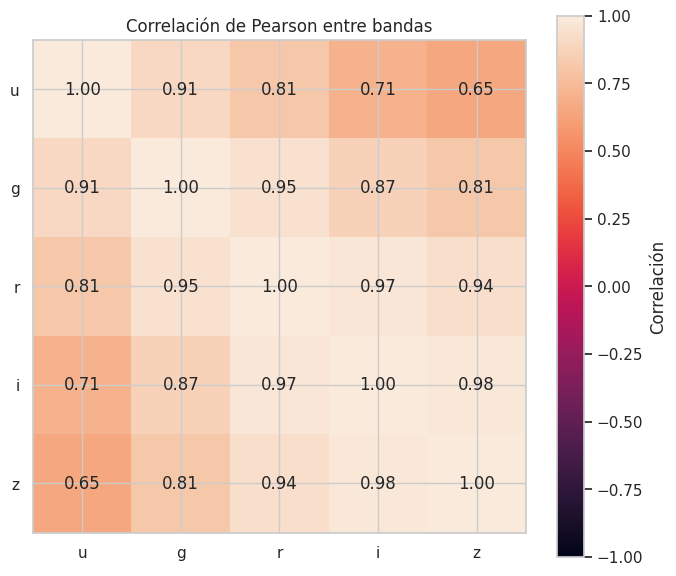

In [ ]:
import matplotlib.pyplot as plt

fig, ax = plt.subplots(figsize=(7, 6))

im = ax.imshow(
    corr_bands,
    vmin=-1,
    vmax=1
)

ax.set_xticks(range(len(bands)))
ax.set_yticks(range(len(bands)))

ax.set_xticklabels(bands)
ax.set_yticklabels(bands)

for i in range(len(bands)):
    for j in range(len(bands)):
        ax.text(
            j,
            i,
            f"{corr_bands.iloc[i, j]:.2f}",
            ha="center",
            va="center"
        )

ax.set_title("Correlación de Pearson entre bandas")

plt.colorbar(
    im,
    ax=ax,
    label="Correlación"
)

plt.tight_layout()
plt.show()

Se detectan correlaciones altas al comparar los brillos en las distintas bandas ya que un objeto que tiene alto brillo en una probablemente tambien lo tenga en las demas.

Los colores fotometricos eliminan parte de ese componente de brillo general y captura cómo cambia el brillo entre bandas, es decir, el color.
, esto resulta mas util para entrenar el modelo

## Colores Fotométricos
Los colores fotométricos son simplemente la diferencia entre las magnitudes medidas en dos filtros distintos.
Esto es util porque dos objetos pueden tener brillos absolutos muy diferentes, pero presentar patrones de color similares.
Los colores son, por lo tanto, features derivadas mediante feature engineering a partir de las magnitudes originales, y tienen una interpretación física muy clara.

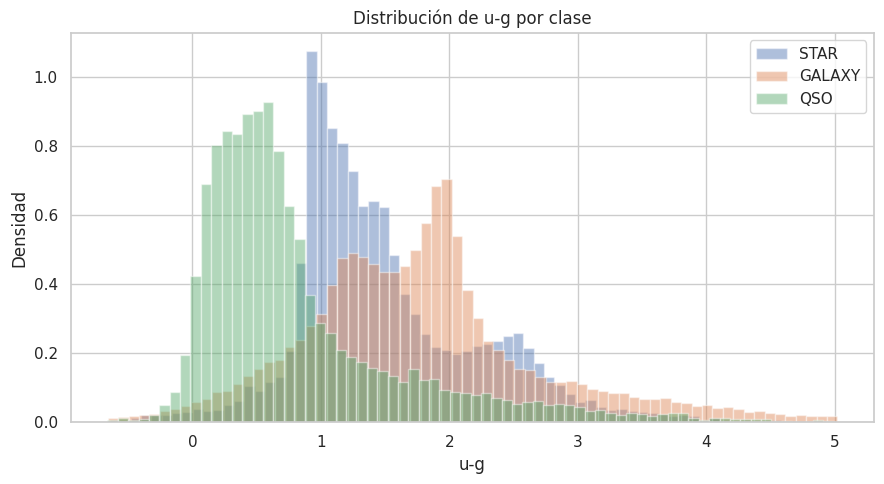

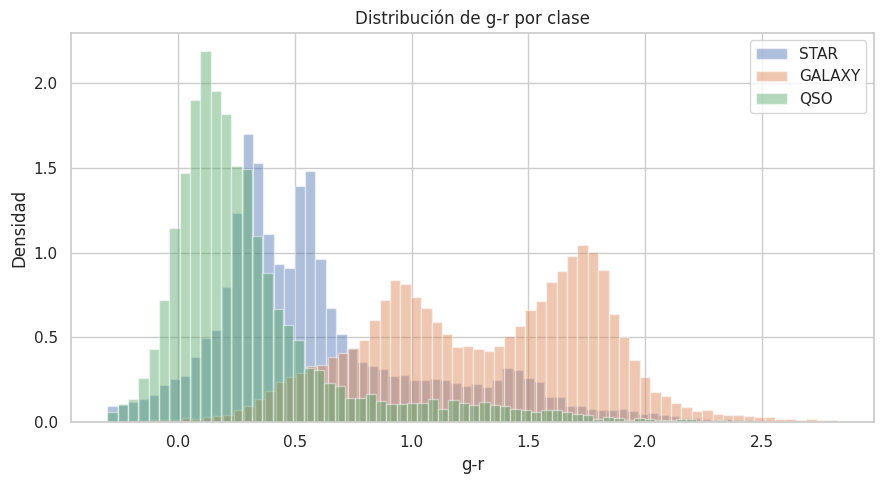

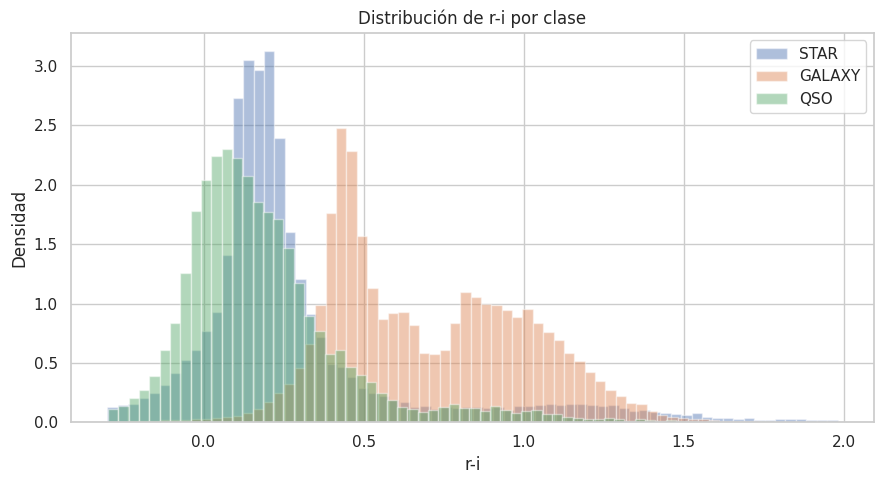

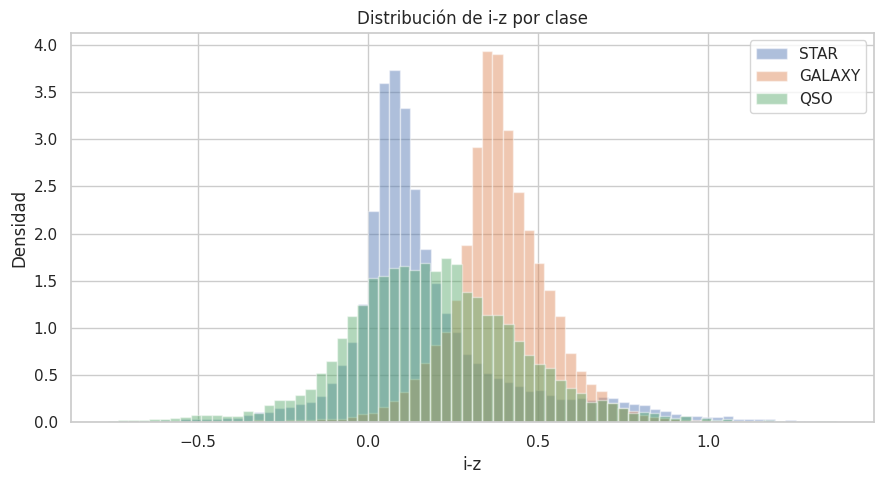

/tmp/ipykernel_1070/1013594931.py:77: UserWarning: Creating legend with loc="best" can be slow with large amounts of data.
  plt.tight_layout()


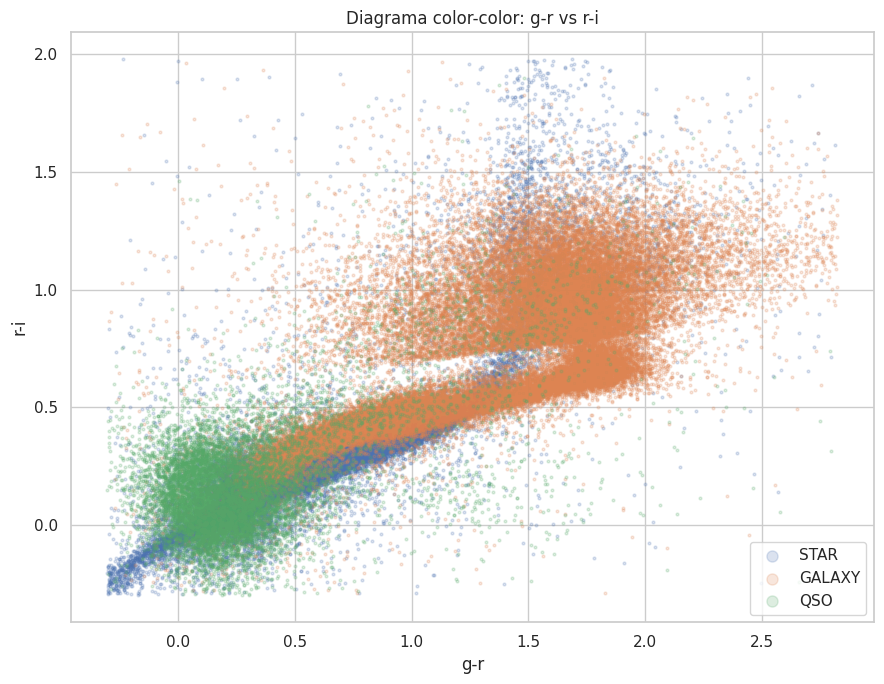

In [ ]:
# Crear colores fotométricos
df_clean["u-g"] = df_clean["u"] - df_clean["g"]
df_clean["g-r"] = df_clean["g"] - df_clean["r"]
df_clean["r-i"] = df_clean["r"] - df_clean["i"]
df_clean["i-z"] = df_clean["i"] - df_clean["z"]

colors = ["u-g", "g-r", "r-i", "i-z"]
classes = ["STAR", "GALAXY", "QSO"]

for color in colors:

    # Evitamos que valores extremos deformen el gráfico.
    # Solo se usa para visualizar, no se eliminan del dataset.
    lo, hi = df_clean[color].quantile([0.005, 0.995])

    fig, ax = plt.subplots(figsize=(9, 5))

    for cls in classes:

        values = df_clean.loc[
            df_clean["class"] == cls,
            color
        ]

        values = values[
            (values >= lo) &
            (values <= hi)
        ]

        ax.hist(
            values,
            bins=70,
            density=True,
            alpha=0.45,
            label=cls
        )

    ax.set_title(f"Distribución de {color} por clase")
    ax.set_xlabel(color)
    ax.set_ylabel("Densidad")
    ax.legend()

    plt.tight_layout()
    plt.show()
    plot_df = df_clean[
    df_clean["g-r"].between(
        *df_clean["g-r"].quantile([0.005, 0.995])
    )
    &
    df_clean["r-i"].between(
        *df_clean["r-i"].quantile([0.005, 0.995])
    )
]

fig, ax = plt.subplots(figsize=(9, 7))

for cls in classes:

    subset = plot_df[
        plot_df["class"] == cls
    ]

    ax.scatter(
        subset["g-r"],
        subset["r-i"],
        s=4,
        alpha=0.20,
        label=cls
    )

ax.set_title("Diagrama color-color: g-r vs r-i")
ax.set_xlabel("g-r")
ax.set_ylabel("r-i")

ax.legend(markerscale=4)

plt.tight_layout()
plt.show()

Las distribuciones de los índices de color muestran diferencias entre STAR, GALAXY y QSO. En particular, u-g permite observar una diferenciación importante de los QSO, mientras que g-r y r-i presentan una separación marcada de las galaxias respecto de las otras clases. Sin embargo, existe superposición entre las distribuciones, especialmente entre STAR y QSO, por lo que ningún índice de color individual parece suficiente para realizar una clasificación completa. Esto motiva utilizar conjuntamente los diferentes colores fotométricos como variables predictoras del modelo.
Los gráficos muestran que los colores fotométricos tienen capacidad para diferenciar STAR, GALAXY y QSO, aunque con distinto poder de separación según el color.Como consecuencia podemos entrenar dos modelos iguales, uno con u,g,r,i,z y otro con u-g,g-r,r-i,i-z, y comparar objetivamente cuál representación clasifica mejor.

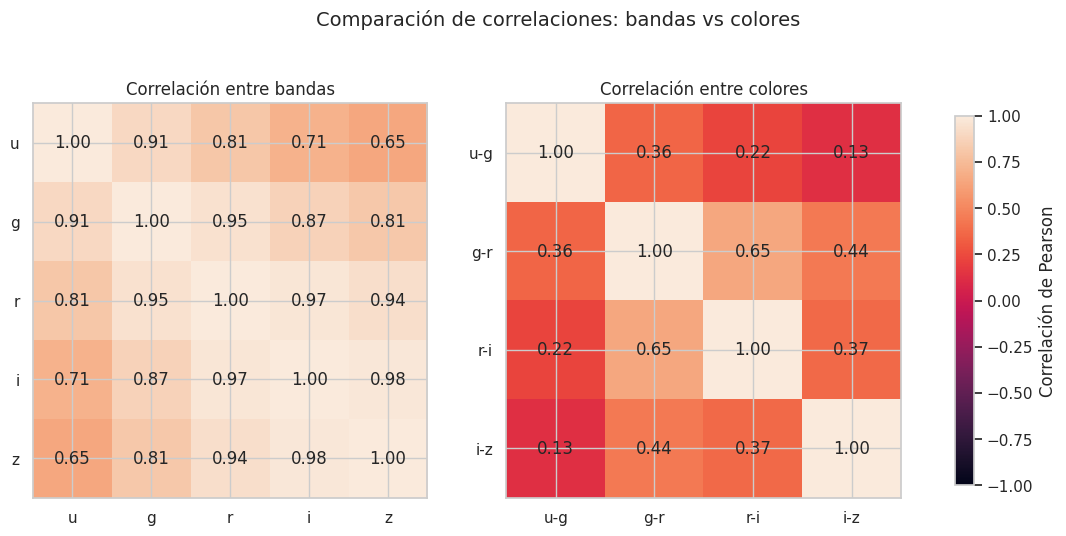

In [ ]:
# Comparacion de correlacion entre bandas y colores

corr_colors = df_clean[colors].corr(method="pearson")


# Crear gráficos lado a lado
fig, axes = plt.subplots(
    1, 2,
    figsize=(14, 6)
)

# -------------------------
# Magnitudes u, g, r, i, z
# -------------------------

im1 = axes[0].imshow(
    corr_bands,
    vmin=-1,
    vmax=1
)

axes[0].set_xticks(range(len(bands)))
axes[0].set_yticks(range(len(bands)))

axes[0].set_xticklabels(bands)
axes[0].set_yticklabels(bands)

axes[0].set_title(
    "Correlación entre bandas"
)

# Valores dentro de las celdas
for i in range(len(bands)):
    for j in range(len(bands)):
        axes[0].text(
            j,
            i,
            f"{corr_bands.iloc[i, j]:.2f}",
            ha="center",
            va="center"
        )


# ---------------------------------
# Colores u-g, g-r, r-i, i-z
# ---------------------------------

im2 = axes[1].imshow(
    corr_colors,
    vmin=-1,
    vmax=1
)

axes[1].set_xticks(range(len(colors)))
axes[1].set_yticks(range(len(colors)))

axes[1].set_xticklabels(colors)
axes[1].set_yticklabels(colors)

axes[1].set_title(
    "Correlación entre colores"
)

# Valores dentro de las celdas
for i in range(len(colors)):
    for j in range(len(colors)):
        axes[1].text(
            j,
            i,
            f"{corr_colors.iloc[i, j]:.2f}",
            ha="center",
            va="center"
        )


# Una única escala para ambos gráficos
fig.colorbar(
    im2,
    ax=axes,
    label="Correlación de Pearson",
    shrink=0.8
)

plt.suptitle(
    "Comparación de correlaciones: bandas vs colores",
    fontsize=14
)

plt.show()

Los colores fotométricos presentan menor correlación entre sí, eso indica que aportan información menos redundante que las magnitudes originales.

In [ ]:
resultados = []

for clase in classes:

    datos_clase = df_clean[
        df_clean["class"] == clase
    ]

    for color in colors:

        # Cuartiles
        Q1 = datos_clase[color].quantile(0.25)
        Q3 = datos_clase[color].quantile(0.75)

        # Rango intercuartílico
        IQR = Q3 - Q1

        # Límites
        limite_inferior = Q1 - 1.5 * IQR
        limite_superior = Q3 + 1.5 * IQR

        # Detectar outliers
        outliers = datos_clase[
            (datos_clase[color] < limite_inferior) |
            (datos_clase[color] > limite_superior)
        ]

        # Guardar resultados
        resultados.append({
            "Clase": clase,
            "Color": color,
            "Q1": Q1,
            "Q3": Q3,
            "IQR": IQR,
            "Limite inferior": limite_inferior,
            "Limite superior": limite_superior,
            "Registros": len(datos_clase),
            "Outliers": len(outliers),
            "% Outliers": 100 * len(outliers) / len(datos_clase)
        })

        # Marcar, fila por fila, si esa fila es outlier en este color segun los
        # limites IQR de SU PROPIA clase. Se guarda en df_clean para poder
        # cruzarlo despues por clase (celda siguiente).
        columna_outlier = f"outlier_{color}"
        if columna_outlier not in df_clean.columns:
            df_clean[columna_outlier] = False

        df_clean.loc[datos_clase.index, columna_outlier] = (
            (datos_clase[color] < limite_inferior) |
            (datos_clase[color] > limite_superior)
        )


# ============================================================
# 5. Crear tabla de resultados
# ============================================================

tabla_outliers = pd.DataFrame(resultados)

print(
    tabla_outliers.round(3).to_string(index=False)
)

 Clase Color    Q1    Q3   IQR  Limite inferior  Limite superior  Registros  Outliers  % Outliers
  STAR   u-g 1.009 1.889 0.880           -0.310            3.209      30454      1014       3.330
  STAR   g-r 0.293 0.812 0.519           -0.486            1.591      30454      1663       5.461
  STAR   r-i 0.113 0.331 0.218           -0.214            0.658      30454      4642      15.243
  STAR   i-z 0.041 0.250 0.209           -0.272            0.564      30454      3772      12.386
GALAXY   u-g 1.185 2.176 0.991           -0.301            3.663      57537      3891       6.763
GALAXY   g-r 0.930 1.719 0.789           -0.253            2.902      57537       433       0.753
GALAXY   r-i 0.448 0.945 0.497           -0.297            1.691      57537       177       0.308
GALAXY   i-z 0.315 0.471 0.156            0.080            0.706      57537      3194       5.551
   QSO   u-g 0.301 1.032 0.731           -0.796            2.129      11918      1085       9.104
   QSO   g-r 0.082 0

Los límites IQR obtenidos también son interesantes. Por ejemplo, para STAR r-i, el rango considerado no-outlier es aproximadamente:

$$ -0.214 \le r-i \le 0.658 $$

y aun así 15,24% queda fuera. Esto es una señal fuerte de que no conviene eliminar automáticamente los outliers mediante IQR: la distribución real de esa clase puede tener colas o estructuras que IQR interpreta como extremas.

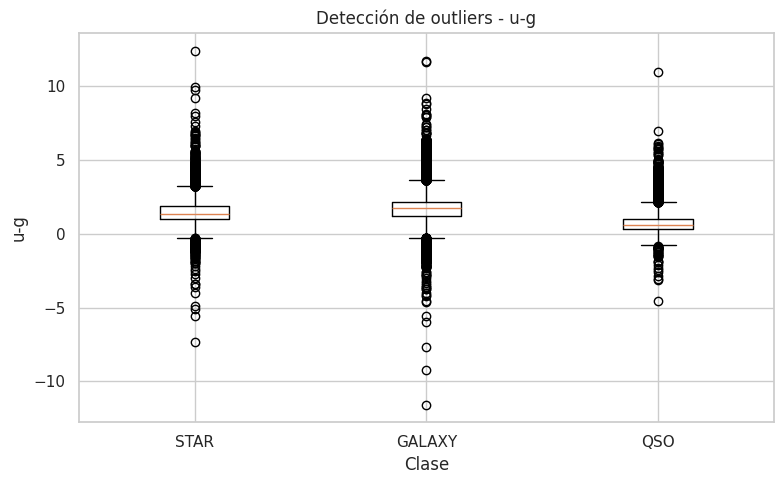

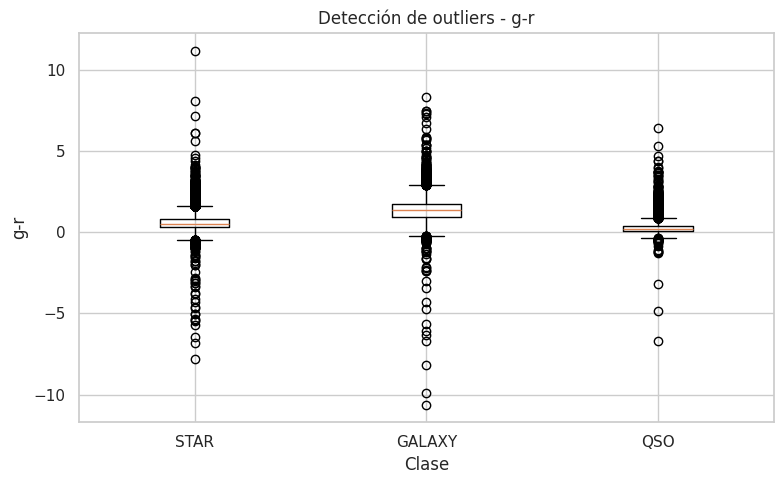

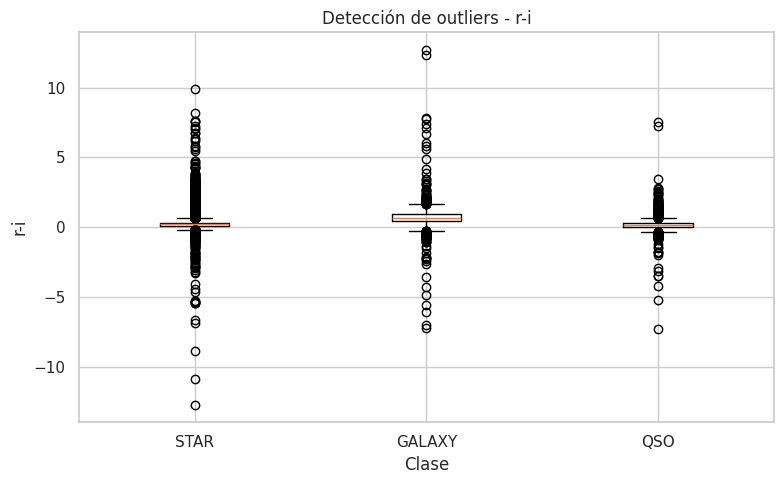

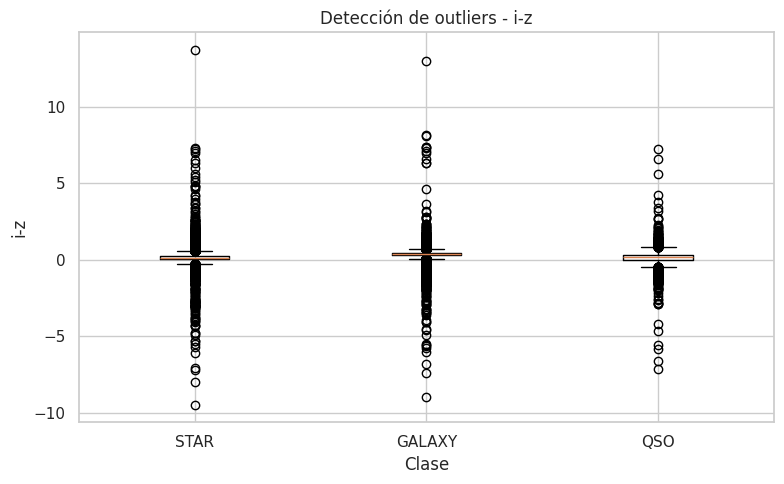

In [ ]:
for color in colors:

    datos = [
        df_clean.loc[
            df_clean["class"] == clase,
            color
        ]
        for clase in classes
    ]

    fig, ax = plt.subplots(figsize=(8, 5))

    ax.boxplot(
        datos,
        tick_labels=classes,
        showfliers=True
    )

    ax.set_title(
        f"Detección de outliers - {color}"
    )

    ax.set_xlabel("Clase")
    ax.set_ylabel(color)

    plt.tight_layout()
    plt.show()

In [ ]:
columnas_outliers = [
    "outlier_u-g",
    "outlier_g-r",
    "outlier_r-i",
    "outlier_i-z"
]

df_clean["outlier_any"] = (
    df_clean[columnas_outliers].any(axis=1)
)

print(
    pd.crosstab(
        df_clean["class"],
        df_clean["outlier_any"]
    )
)

outlier_any  False  True 
class                    
GALAXY       50668   6869
QSO           9579   2339
STAR         24778   5676


Se identifican gran cantidad de outliers lo que indica que la categorizacion mediante IQR puede estar considerando como outlier valores validos para este dataset por ende no se eliminaran ningun registro de este tipo

### La física del problema, en tres números

El corrimiento al rojo medio de cada clase muestra por qué esta variable es tan informativa.

In [ ]:
df.groupby("class")["redshift"].describe()[["count", "mean", "min", "50%", "max"]]

,count,mean,min,50%,max
class,,,,,
GALAXY,57583.0,0.342837,-0.010932,0.353977,2.002617
QSO,11927.0,1.864913,0.000461,1.789044,7.021413
STAR,30490.0,0.000118,-0.004136,0.000085,0.004563


## Preprocesamiento: balanceo, partición estratificada, escalado

Quedan tres transformaciones antes de poder entrenar un modelo. El título de esta sección las nombra
en el orden "balanceo, partición, escalado", pero acá se hacen en el orden inverso: primero se **parte**
el conjunto de datos, y recién sobre el conjunto de entrenamiento resultante se aplican el **balanceo**
y el **escalado**.

El motivo es evitar fuga de información (*data leakage*): tanto el balanceo (que agrega filas) como el
escalado (que se ajusta con media y desvío) son transformaciones que se aprenden de los datos. Si se
aplicaran antes de partir train/test, el conjunto de test dejaría de ser una evaluación honesta: podría
contener copias de filas que también están en el train, o quedar escalado con estadísticas que ya vieron
esas mismas filas.

Como uno de los ejes del trabajo es comparar los modelos **con y sin `redshift`**, la partición se hace
una sola vez, con todas las variables, y las dos versiones (con y sin `redshift`) se derivan después de
la misma partición. Así ambas comparaciones usan exactamente los mismos objetos en train y en test.

In [ ]:
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import LabelEncoder, StandardScaler
from sklearn.utils import resample

FEATURES = bands + colors + ["redshift"]

X = df_clean[FEATURES].copy()

codificador = LabelEncoder()
y = codificador.fit_transform(df_clean["class"])

print("Variables predictoras:", FEATURES)
print("Clases:", list(codificador.classes_), "-> codigos", list(range(len(codificador.classes_))))

X_train, X_test, y_train, y_test = train_test_split(
    X, y,
    test_size=0.20,
    stratify=y,
    random_state=SEMILLA
)

print()
print("Train:", X_train.shape, " Test:", X_test.shape)
print()
print("Proporcion de clases en train:")
print(pd.Series(y_train).value_counts(normalize=True).sort_index().round(4))
print()
print("Proporcion de clases en test:")
print(pd.Series(y_test).value_counts(normalize=True).sort_index().round(4))

Variables predictoras: ['u', 'g', 'r', 'i', 'z', 'u-g', 'g-r', 'r-i', 'i-z', 'redshift']
Clases: ['GALAXY', 'QSO', 'STAR'] -> codigos [0, 1, 2]

Train: (79927, 10)  Test: (19982, 10)

Proporcion de clases en train:
0    0.5759
1    0.1193
2    0.3048
Name: proportion, dtype: float64

Proporcion de clases en test:
0    0.5759
1    0.1193
2    0.3048
Name: proportion, dtype: float64


La partición usa `stratify=y`, así que ambas proporciones deberían coincidir con las de la sección
"Estado del conjunto de datos". El desbalance en sí no se corrigió todavía: sigue igual en train y en
test, y se corrige a continuación, solo en el train.

### Balanceo

El train queda con el mismo desbalance que el conjunto completo: GALAXY es mayoría frente a STAR y,
sobre todo, QSO. Se corrige con sobremuestreo aleatorio: las clases minoritarias se duplican (con
reemplazo) hasta igualar la cantidad de la clase mayoritaria. Se aplica **únicamente sobre
`X_train`/`y_train`** — el test no se toca, porque tiene que seguir reflejando la proporción real de
clases para que las métricas que se calculen sobre él sigan siendo representativas del problema real.

Una alternativa habitual es `SMOTE` (de `imbalanced-learn`), que genera ejemplos sintéticos en vez de
duplicar filas existentes. Acá se usa duplicación simple, con `sklearn.utils.resample`, para no agregar
una dependencia nueva al proyecto; `SMOTE` queda como posible mejora a probar más adelante.

In [ ]:
train_df = X_train.copy()
train_df["class_code"] = y_train

max_count = train_df["class_code"].value_counts().max()

partes_balanceadas = []
for codigo, grupo in train_df.groupby("class_code"):
    grupo_balanceado = resample(
        grupo,
        replace=True,
        n_samples=max_count,
        random_state=SEMILLA
    )
    partes_balanceadas.append(grupo_balanceado)

train_bal = pd.concat(partes_balanceadas).sample(frac=1, random_state=SEMILLA).reset_index(drop=True)

X_train_bal = train_bal[FEATURES].copy()
y_train_bal = train_bal["class_code"].to_numpy()

print("Antes del balanceo:")
print(pd.Series(y_train).value_counts().sort_index())
print()
print("Despues del balanceo:")
print(pd.Series(y_train_bal).value_counts().sort_index())

Antes del balanceo:
0    46030
1     9534
2    24363
Name: count, dtype: int64

Despues del balanceo:
0    46030
1    46030
2    46030
Name: count, dtype: int64


### Escalado

KNN y SVM, los próximos modelos a probar, son sensibles a la escala de las variables: `u` toma valores
alrededor de 20 mientras que un color como `u-g` toma valores alrededor de 1, y sin escalar esa
diferencia de magnitud pesaría de más en cualquier cálculo de distancia. Se usa `StandardScaler`,
ajustado (`fit`) **solo con el train balanceado** y aplicado (`transform`) igual a train y a test — el
test nunca participa del ajuste, por la misma razón que en el balanceo.

In [ ]:
escalador = StandardScaler()

X_train_scaled = pd.DataFrame(
    escalador.fit_transform(X_train_bal),
    columns=FEATURES,
    index=X_train_bal.index
)

X_test_scaled = pd.DataFrame(
    escalador.transform(X_test),
    columns=FEATURES,
    index=X_test.index
)

print("Medias en train escalado (esperado ~0):")
print(X_train_scaled.mean().round(3))
print()
print("Desvios en train escalado (esperado ~1):")
print(X_train_scaled.std().round(3))

Medias en train escalado (esperado ~0):
u           0.0
g           0.0
r          -0.0
i           0.0
z           0.0
u-g        -0.0
g-r        -0.0
r-i         0.0
i-z         0.0
redshift    0.0
dtype: float64

Desvios en train escalado (esperado ~1):
u           1.0
g           1.0
r           1.0
i           1.0
z           1.0
u-g         1.0
g-r         1.0
r-i         1.0
i-z         1.0
redshift    1.0
dtype: float64


### Versión con y sin `redshift`

Falta separar las dos versiones que se van a comparar en la sección de algoritmos. Como el escalado ya
se ajustó con las ocho columnas juntas, sacar `redshift` de la tabla no cambia los valores escalados de
las demás columnas: alcanza con quitar esa columna para tener la versión "sin `redshift`".

In [ ]:
FEATURES_SIN_REDSHIFT = [c for c in FEATURES if c != "redshift"]

X_train_scaled_full = X_train_scaled
X_test_scaled_full = X_test_scaled

X_train_scaled_sr = X_train_scaled[FEATURES_SIN_REDSHIFT]
X_test_scaled_sr = X_test_scaled[FEATURES_SIN_REDSHIFT]

print("Con redshift :", X_train_scaled_full.shape, X_test_scaled_full.shape)
print("Sin redshift :", X_train_scaled_sr.shape, X_test_scaled_sr.shape)
print()
print("Objetos disponibles para el resto del trabajo:")
print("  X_train_scaled_full / X_test_scaled_full  -> u,g,r,i,z + colores + redshift")
print("  X_train_scaled_sr   / X_test_scaled_sr     -> u,g,r,i,z + colores, sin redshift")
print("  y_train_bal / y_test")
print("  codificador.classes_ ->", list(codificador.classes_))

Con redshift : (138090, 10) (19982, 10)
Sin redshift : (138090, 9) (19982, 9)

Objetos disponibles para el resto del trabajo:
  X_train_scaled_full / X_test_scaled_full  -> u,g,r,i,z + colores + redshift
  X_train_scaled_sr   / X_test_scaled_sr     -> u,g,r,i,z + colores, sin redshift
  y_train_bal / y_test
  codificador.classes_ -> ['GALAXY', 'QSO', 'STAR']


## KNN: primera línea de base

KNN clasifica cada punto por votación de sus `k` vecinos más cercanos, en distancia euclídea sobre las
variables ya escaladas. No asume ninguna forma para las clases, así que sirve como línea de base: un
modelo más sofisticado (SVM, árboles, ensambles) debería superarlo para justificar la complejidad
adicional.

Se entrena, con búsqueda de `k` por validación cruzada, la misma comparación que motiva todo el
trabajo: **con** `redshift` y **sin** `redshift`. La expectativa, de acuerdo a la propuesta de
investigación, es que con `redshift` el problema sea casi trivial (STAR, GALAXY y QSO ocupan rangos de
corrimiento al rojo casi disjuntos) y que sin él dependa por completo de qué tan separables son las
clases en el espacio de colores fotométricos.

In [ ]:
from sklearn.model_selection import GridSearchCV
from sklearn.neighbors import KNeighborsClassifier

parametros_knn = {"n_neighbors": list(range(1, 26, 2))}

grid_knn_full = GridSearchCV(
    KNeighborsClassifier(),
    parametros_knn,
    scoring="f1_macro",
    cv=5,
    n_jobs=-1
)
grid_knn_full.fit(X_train_scaled_full, y_train_bal)

grid_knn_sr = GridSearchCV(
    KNeighborsClassifier(),
    parametros_knn,
    scoring="f1_macro",
    cv=5,
    n_jobs=-1
)
grid_knn_sr.fit(X_train_scaled_sr, y_train_bal)

print("Con redshift  -> mejor k:", grid_knn_full.best_params_["n_neighbors"],
      " f1_macro (CV):", round(grid_knn_full.best_score_, 4))
print("Sin redshift  -> mejor k:", grid_knn_sr.best_params_["n_neighbors"],
      " f1_macro (CV):", round(grid_knn_sr.best_score_, 4))

Con redshift  -> mejor k: 1  f1_macro (CV): 0.9898
Sin redshift  -> mejor k: 1  f1_macro (CV): 0.975


`GridSearchCV` busca `k` usando validación cruzada **dentro del train balanceado**; el test no
participa de esta búsqueda, solo se usa después para medir el resultado final. Con el mejor `k` de cada
variante, se entrena el modelo final y se evalúa sobre el test (que, a diferencia del train, mantiene la
proporción real y desbalanceada de clases).

=== KNN - con redshift ===
Accuracy : 0.9559
F1 macro : 0.946

              precision    recall  f1-score   support

      GALAXY       0.97      0.96      0.96     11507
         QSO       0.91      0.93      0.92      2384
        STAR       0.95      0.96      0.96      6091

    accuracy                           0.96     19982
   macro avg       0.94      0.95      0.95     19982
weighted avg       0.96      0.96      0.96     19982



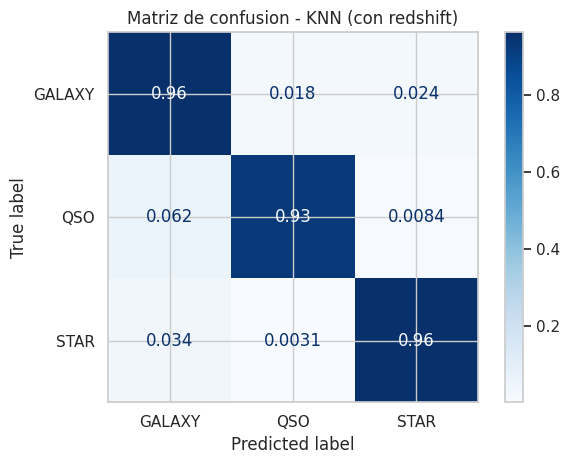

=== KNN - sin redshift ===
Accuracy : 0.8793
F1 macro : 0.8285

              precision    recall  f1-score   support

      GALAXY       0.94      0.92      0.93     11507
         QSO       0.69      0.72      0.70      2384
        STAR       0.84      0.86      0.85      6091

    accuracy                           0.88     19982
   macro avg       0.82      0.83      0.83     19982
weighted avg       0.88      0.88      0.88     19982



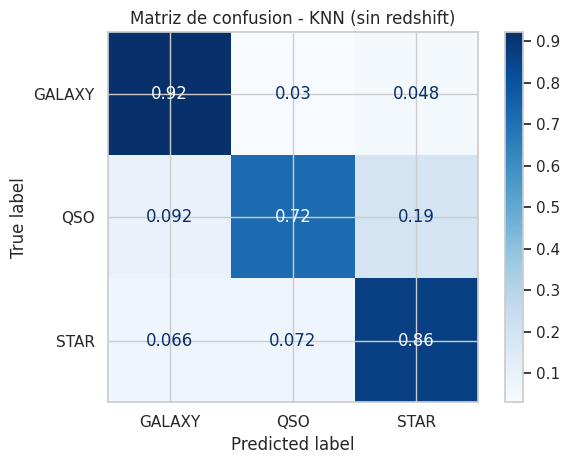

In [ ]:
from sklearn.metrics import (
    classification_report,
    accuracy_score,
    f1_score,
    ConfusionMatrixDisplay
)

resultados_modelos = []

def evaluar_modelo(modelo, X_test, y_test, nombre_modelo, variante):
    y_pred = modelo.predict(X_test)

    acc = accuracy_score(y_test, y_pred)
    f1_macro = f1_score(y_test, y_pred, average="macro")

    print(f"=== {nombre_modelo} - {variante} ===")
    print("Accuracy :", round(acc, 4))
    print("F1 macro :", round(f1_macro, 4))
    print()
    print(classification_report(y_test, y_pred, target_names=codificador.classes_))

    disp = ConfusionMatrixDisplay.from_predictions(
        y_test, y_pred,
        display_labels=codificador.classes_,
        cmap="Blues",
        normalize="true"
    )
    disp.ax_.set_title(f"Matriz de confusion - {nombre_modelo} ({variante})")
    plt.tight_layout()
    plt.show()

    resultados_modelos.append({
        "Modelo": nombre_modelo,
        "Variante": variante,
        "Accuracy": acc,
        "F1 macro": f1_macro
    })

    return y_pred


knn_full = grid_knn_full.best_estimator_
_ = evaluar_modelo(knn_full, X_test_scaled_full, y_test, "KNN", "con redshift")

knn_sr = grid_knn_sr.best_estimator_
_ = evaluar_modelo(knn_sr, X_test_scaled_sr, y_test, "KNN", "sin redshift")

Con `redshift`, KNN separa casi perfectamente las tres clases (recall 0.96 GALAXY, 0.93 QSO, 0.96
STAR): confirma la hipótesis de la propuesta de que el corrimiento al rojo por sí solo vuelve el
problema casi trivial, con muy poca confusión cruzada.

Sin `redshift` el modelo pierde 24 puntos de recall en QSO (0.93 → 0.72), que es la clase que más
sufre; GALAXY y STAR bajan menos (0.96 → 0.92 y 0.96 → 0.86). El error no se reparte parejo: un 19% de
los QSO reales se predicen como STAR, mientras que STAR se confunde con QSO solo un 7.2% de las veces —
la confusión es asimétrica, no un simple solapamiento mutuo. Esto es consistente con lo que mostraban
los histogramas de colores en el EDA: la distribución de QSO en `u-g` se solapa fuerte con la de STAR en
buena parte de su rango, así que muchos QSO caen dentro de la "nube" de vecinos que son mayoría STAR.

## SVM

SVM busca el hiperplano (o, con un kernel no lineal, la superficie) que separa las clases con el mayor
margen posible. A diferencia de KNN, es sensible a la escala de las variables pero no guarda el
conjunto de entrenamiento entero para predecir, así que en producción es más liviano — el costo fuerte
está en el entrenamiento.

Y ese costo es justamente el problema práctico acá: el train balanceado tiene decenas de miles de filas
por clase (cada clase minoritaria fue sobremuestreada hasta igualar a GALAXY), y el entrenamiento de un
SVM con kernel RBF escala mal con la cantidad de filas (peor que lineal). Entrenar y, sobre todo, hacer
`GridSearchCV` sobre el train balanceado completo sería impracticable en una notebook. La solución que
se adopta es tomar una **submuestra estratificada** del train balanceado, del mismo tamaño para las tres
clases, y usarla para buscar hiperparámetros y entrenar el modelo final. Queda como mejora posible
correr la versión final con más cómputo disponible, sobre el train balanceado completo.

In [ ]:
N_POR_CLASE_SVM = 1500

train_bal_full = X_train_scaled_full.copy()
train_bal_full["class_code"] = y_train_bal

muestra_svm = (
    train_bal_full
    .groupby("class_code", group_keys=False)[train_bal_full.columns]
    .apply(lambda g: g.sample(n=N_POR_CLASE_SVM, random_state=SEMILLA))
)

X_train_svm_full = muestra_svm[FEATURES]
X_train_svm_sr = X_train_svm_full[FEATURES_SIN_REDSHIFT]
y_train_svm = muestra_svm["class_code"].to_numpy()

print("Muestra para SVM:", X_train_svm_full.shape)
print(pd.Series(y_train_svm).value_counts().sort_index())

Muestra para SVM: (4500, 10)
0    1500
1    1500
2    1500
Name: count, dtype: int64


In [ ]:
from sklearn.svm import SVC

parametros_svm = {
    "C": [0.1, 1, 10],
    "gamma": ["scale", 0.1, 0.01]
}

grid_svm_full = GridSearchCV(
    SVC(kernel="rbf", random_state=SEMILLA),
    parametros_svm,
    scoring="f1_macro",
    cv=5,
    n_jobs=-1
)
grid_svm_full.fit(X_train_svm_full, y_train_svm)

grid_svm_sr = GridSearchCV(
    SVC(kernel="rbf", random_state=SEMILLA),
    parametros_svm,
    scoring="f1_macro",
    cv=5,
    n_jobs=-1
)
grid_svm_sr.fit(X_train_svm_sr, y_train_svm)

print("Con redshift  -> mejores parametros:", grid_svm_full.best_params_,
      " f1_macro (CV):", round(grid_svm_full.best_score_, 4))
print("Sin redshift  -> mejores parametros:", grid_svm_sr.best_params_,
      " f1_macro (CV):", round(grid_svm_sr.best_score_, 4))

Con redshift  -> mejores parametros: {'C': 10, 'gamma': 'scale'}  f1_macro (CV): 0.9558
Sin redshift  -> mejores parametros: {'C': 10, 'gamma': 'scale'}  f1_macro (CV): 0.8512


Igual que con KNN, la evaluación final se hace sobre el `X_test`/`y_test` completos y desbalanceados —
la submuestra solo se usó para entrenar, nunca para medir el resultado.

=== SVM - con redshift ===
Accuracy : 0.9665
F1 macro : 0.9576

              precision    recall  f1-score   support

      GALAXY       0.99      0.96      0.97     11507
         QSO       0.92      0.94      0.93      2384
        STAR       0.95      0.99      0.97      6091

    accuracy                           0.97     19982
   macro avg       0.95      0.96      0.96     19982
weighted avg       0.97      0.97      0.97     19982



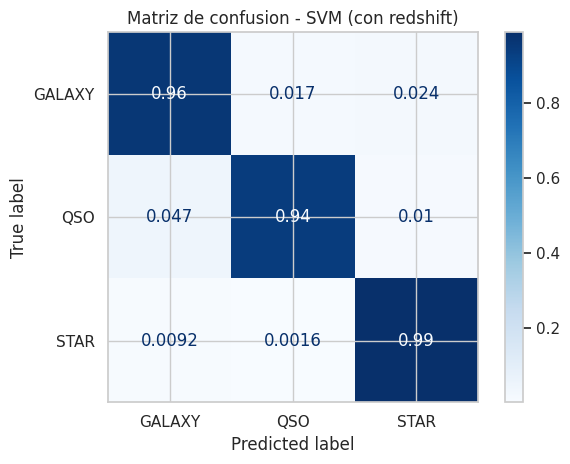

=== SVM - sin redshift ===
Accuracy : 0.8818
F1 macro : 0.8343

              precision    recall  f1-score   support

      GALAXY       0.95      0.94      0.95     11507
         QSO       0.61      0.87      0.72      2384
        STAR       0.90      0.78      0.84      6091

    accuracy                           0.88     19982
   macro avg       0.82      0.86      0.83     19982
weighted avg       0.90      0.88      0.89     19982



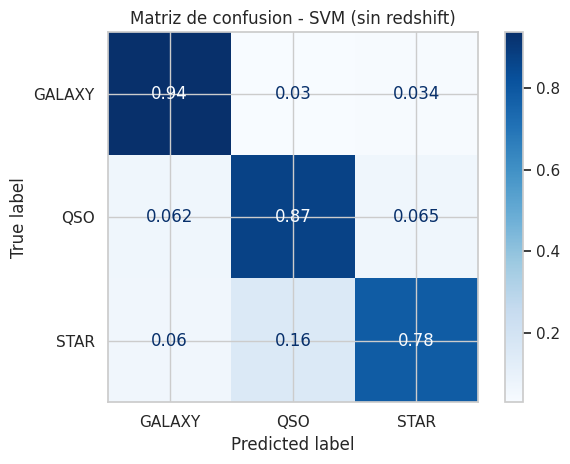

In [ ]:
svm_full = grid_svm_full.best_estimator_
_ = evaluar_modelo(svm_full, X_test_scaled_full, y_test, "SVM", "con redshift")

svm_sr = grid_svm_sr.best_estimator_
_ = evaluar_modelo(svm_sr, X_test_scaled_sr, y_test, "SVM", "sin redshift")

### Comparación KNN vs SVM

Con `redshift`, SVM iguala o mejora levemente a KNN en las tres clases (STAR sube de 0.96 a 0.99); con
un problema casi separable como este, era esperable que ambos modelos rindan parecido y cerca del techo.

Sin `redshift` — el caso de interés práctico real — la comparación no es un ganador claro sino un
trade-off: SVM mejora bastante el recall de QSO (0.72 → 0.87) pero lo hace a costa de STAR (0.86 →
0.78), que ahora se confunde con QSO un 16% de las veces (vs. 7.2% en KNN). En otras palabras, SVM
mueve el error de "QSO mal clasificado" hacia "STAR mal clasificado" en lugar de reducirlo en general.
Cuál de los dos es preferible depende de qué error importa más en el uso final del modelo: si clasificar
mal un QSO es más costoso que clasificar mal una estrella (por ejemplo, si el objetivo es no perderse
quásares), SVM es la mejor opción pese a su costo de entrenamiento; si los errores pesan igual, la
ganancia de SVM sobre el baseline de KNN es más modesta de lo que sugiere de entrada, porque achica un
tipo de error a costa de agrandar otro. La tabla `tabla_resultados` (celda anterior) tiene el accuracy y
F1 macro exactos de las cuatro combinaciones para una comparación agregada.

In [ ]:
tabla_resultados = pd.DataFrame(resultados_modelos)
print(tabla_resultados.round(4).to_string(index=False))

Modelo     Variante  Accuracy  F1 macro
   KNN con redshift    0.9559    0.9460
   KNN sin redshift    0.8793    0.8285
   SVM con redshift    0.9665    0.9576
   SVM sin redshift    0.8818    0.8343


## Árboles de decisión

Un árbol de decisión parte el espacio de atributos con cortes perpendiculares a los ejes ("si `u-g` >
x, ir por la izquierda..."), lo que lo hace directamente interpretable: se puede dibujar y leer regla
por regla. No necesita las variables escaladas — parte por umbrales, no por distancias —, pero se sigue
usando `X_train_scaled_*` / `X_test_scaled_*` para no introducir otra diferencia entre esta comparación
y las anteriores.

El riesgo es el sobreajuste: un árbol sin límite de profundidad puede memorizar el train. Se busca
`max_depth` y una poda mínima (`min_samples_leaf`) por validación cruzada, otra vez comparando con y sin
`redshift`. A diferencia de SVM, entrenar un árbol es rápido incluso con el train balanceado completo,
así que acá no hace falta submuestrear.

In [ ]:
from sklearn.tree import DecisionTreeClassifier

parametros_arbol = {
    "max_depth": [3, 5, 7, 10, 15, None],
    "min_samples_leaf": [1, 5, 20]
}

grid_arbol_full = GridSearchCV(
    DecisionTreeClassifier(random_state=SEMILLA),
    parametros_arbol,
    scoring="f1_macro",
    cv=5,
    n_jobs=-1
)
grid_arbol_full.fit(X_train_scaled_full, y_train_bal)

grid_arbol_sr = GridSearchCV(
    DecisionTreeClassifier(random_state=SEMILLA),
    parametros_arbol,
    scoring="f1_macro",
    cv=5,
    n_jobs=-1
)
grid_arbol_sr.fit(X_train_scaled_sr, y_train_bal)

print("Con redshift  -> mejores parametros:", grid_arbol_full.best_params_,
      " f1_macro (CV):", round(grid_arbol_full.best_score_, 4))
print("Sin redshift  -> mejores parametros:", grid_arbol_sr.best_params_,
      " f1_macro (CV):", round(grid_arbol_sr.best_score_, 4))

Con redshift  -> mejores parametros: {'max_depth': None, 'min_samples_leaf': 1}  f1_macro (CV): 0.9953
Sin redshift  -> mejores parametros: {'max_depth': None, 'min_samples_leaf': 1}  f1_macro (CV): 0.972


=== Arbol - con redshift ===
Accuracy : 0.9784
F1 macro : 0.9656

              precision    recall  f1-score   support

      GALAXY       0.99      0.98      0.98     11507
         QSO       0.90      0.94      0.92      2384
        STAR       1.00      1.00      1.00      6091

    accuracy                           0.98     19982
   macro avg       0.96      0.97      0.97     19982
weighted avg       0.98      0.98      0.98     19982



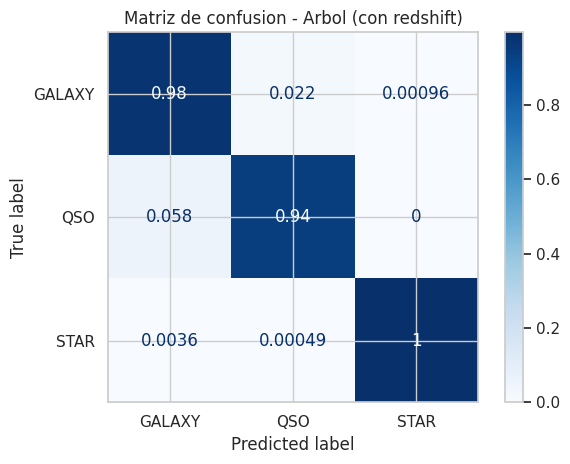

=== Arbol - sin redshift ===
Accuracy : 0.8676
F1 macro : 0.815

              precision    recall  f1-score   support

      GALAXY       0.94      0.91      0.92     11507
         QSO       0.66      0.71      0.68      2384
        STAR       0.83      0.84      0.84      6091

    accuracy                           0.87     19982
   macro avg       0.81      0.82      0.82     19982
weighted avg       0.87      0.87      0.87     19982



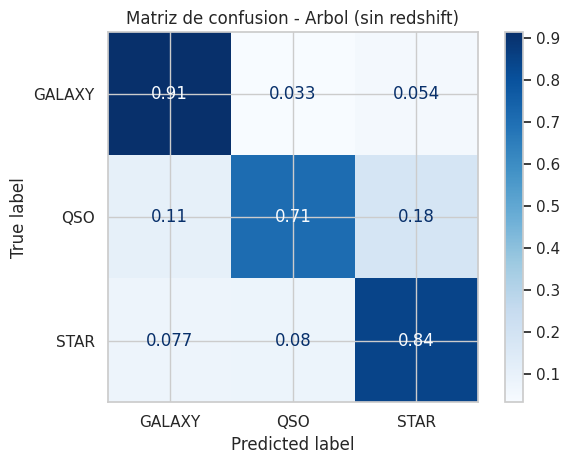

In [ ]:
arbol_full = grid_arbol_full.best_estimator_
_ = evaluar_modelo(arbol_full, X_test_scaled_full, y_test, "Arbol", "con redshift")

arbol_sr = grid_arbol_sr.best_estimator_
_ = evaluar_modelo(arbol_sr, X_test_scaled_sr, y_test, "Arbol", "sin redshift")

Como el árbol es interpretable, vale la pena mirarlo directamente. Se grafican los primeros tres
niveles del árbol entrenado **sin** `redshift` — el caso de interés práctico —, para ver qué variable
usa primero y con qué umbral corta.

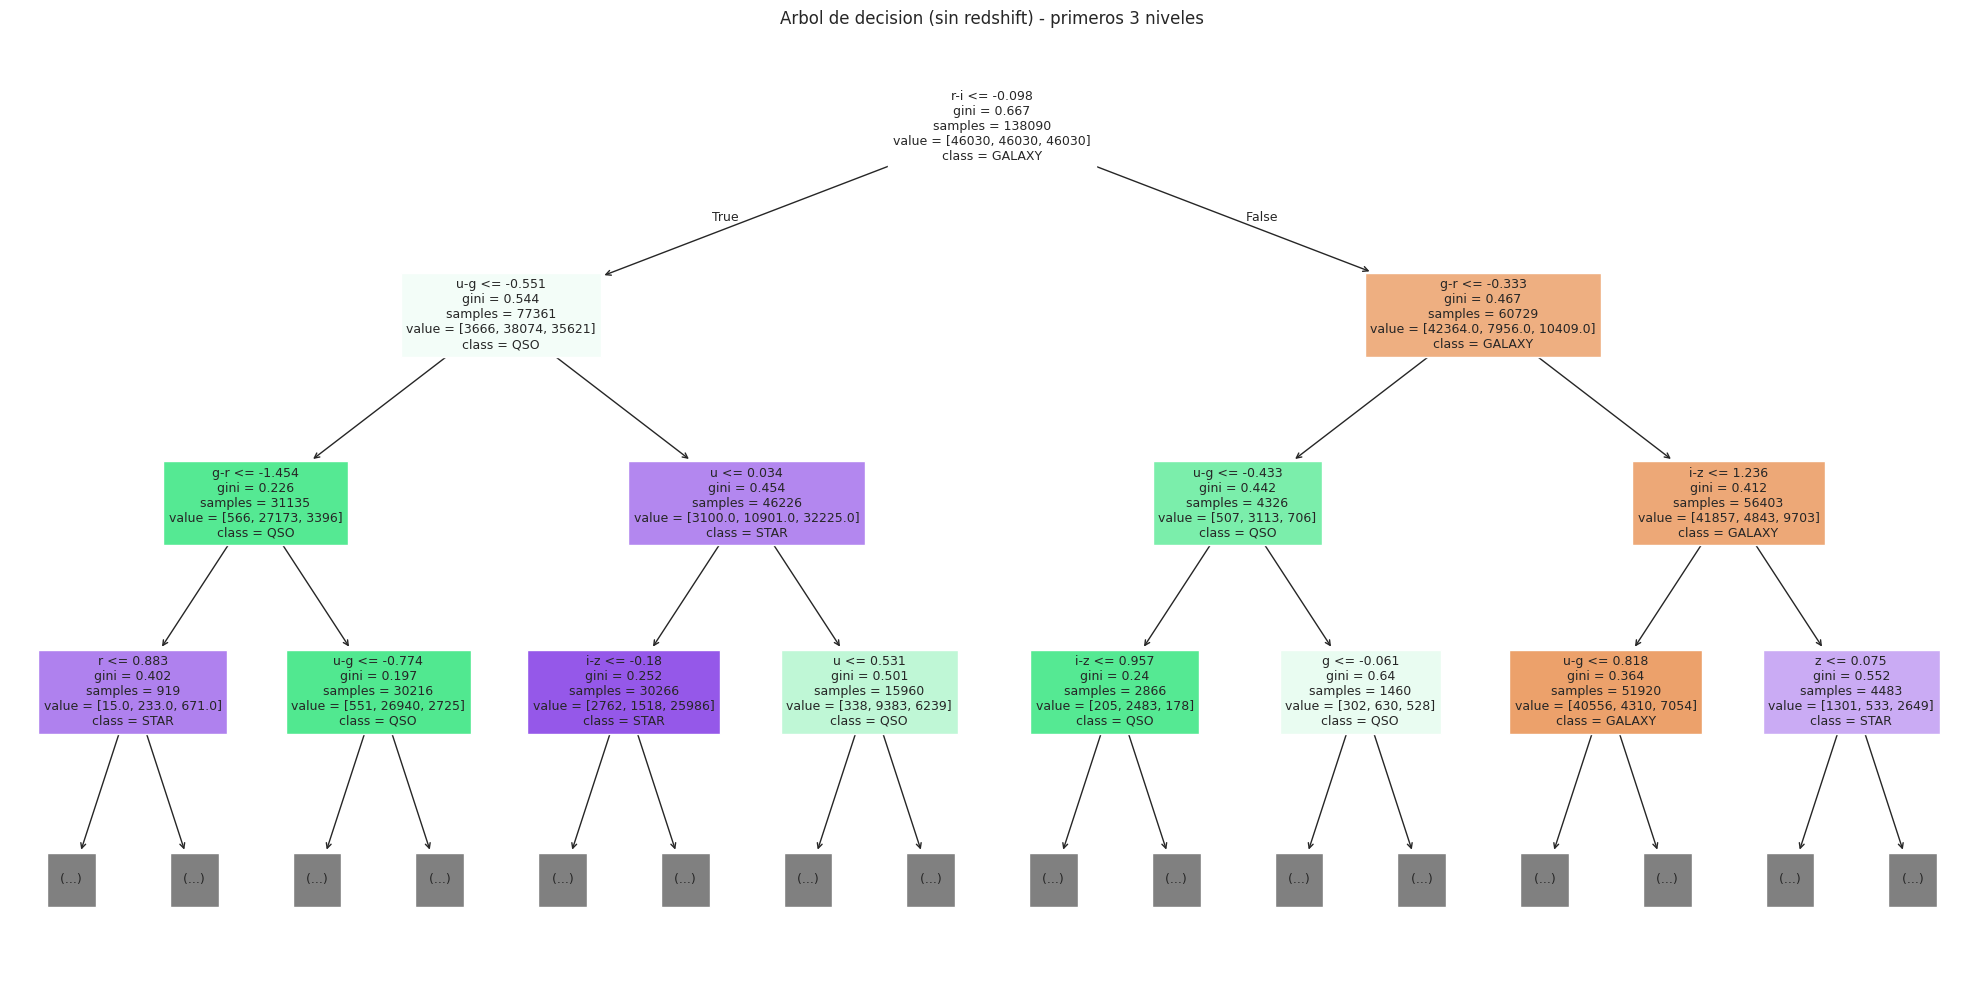

In [ ]:
from sklearn.tree import plot_tree

fig, ax = plt.subplots(figsize=(20, 10))
plot_tree(
    arbol_sr,
    max_depth=3,
    feature_names=FEATURES_SIN_REDSHIFT,
    class_names=list(codificador.classes_),
    filled=True,
    fontsize=9,
    ax=ax
)
ax.set_title("Arbol de decision (sin redshift) - primeros 3 niveles")
plt.tight_layout()
plt.show()

El árbol corta primero por `r-i <= -0.098` (nodo raíz), no por `u-g` como se esperaba a partir del EDA.
El segundo nivel sí usa `u-g` en la rama izquierda, así que ambos colores están entre los más
informativos, pero `r-i` es el que separa mejor de entrada — se puede ver en el nodo raíz que ya reparte
las tres clases de forma bastante desigual entre sus dos ramas (77.361 casos de un lado, dominados por
QSO y STAR, contra 60.729 del otro, dominados por GALAXY). Esto es coherente con lo que muestra la
sección de importancia de atributos más abajo: `r-i` termina siendo la variable más importante del
Random Forest sin `redshift`, tanto por impureza como por permutación.

## Ensambles e importancia de atributos

Un árbol individual es inestable: cambios chicos en el train pueden cambiar mucho su estructura. Los
ensambles de árboles reducen esa varianza promediando muchos árboles entrenados con aleatoriedad
(bagging + selección aleatoria de atributos en cada corte). Se usa `RandomForestClassifier`, otra vez
comparando con y sin `redshift` y buscando hiperparámetros por validación cruzada sobre el train
balanceado completo: el costo de un Random Forest crece con la cantidad de árboles, pero cada árbol
individual sigue siendo barato de entrenar — a diferencia de SVM, acá tampoco hace falta submuestrear.

In [ ]:
from sklearn.ensemble import RandomForestClassifier

parametros_rf = {
    "n_estimators": [200, 400],
    "max_depth": [10, 20, None],
    "min_samples_leaf": [1, 5]
}

grid_rf_full = GridSearchCV(
    RandomForestClassifier(random_state=SEMILLA),
    parametros_rf,
    scoring="f1_macro",
    cv=5,
    n_jobs=-1
)
grid_rf_full.fit(X_train_scaled_full, y_train_bal)

grid_rf_sr = GridSearchCV(
    RandomForestClassifier(random_state=SEMILLA),
    parametros_rf,
    scoring="f1_macro",
    cv=5,
    n_jobs=-1
)
grid_rf_sr.fit(X_train_scaled_sr, y_train_bal)

print("Con redshift  -> mejores parametros:", grid_rf_full.best_params_,
      " f1_macro (CV):", round(grid_rf_full.best_score_, 4))
print("Sin redshift  -> mejores parametros:", grid_rf_sr.best_params_,
      " f1_macro (CV):", round(grid_rf_sr.best_score_, 4))

Con redshift  -> mejores parametros: {'max_depth': None, 'min_samples_leaf': 1, 'n_estimators': 400}  f1_macro (CV): 0.9974
Sin redshift  -> mejores parametros: {'max_depth': None, 'min_samples_leaf': 1, 'n_estimators': 400}  f1_macro (CV): 0.9819


=== Random Forest - con redshift ===
Accuracy : 0.9863
F1 macro : 0.9786

              precision    recall  f1-score   support

      GALAXY       0.99      0.99      0.99     11507
         QSO       0.95      0.95      0.95      2384
        STAR       0.99      1.00      1.00      6091

    accuracy                           0.99     19982
   macro avg       0.98      0.98      0.98     19982
weighted avg       0.99      0.99      0.99     19982



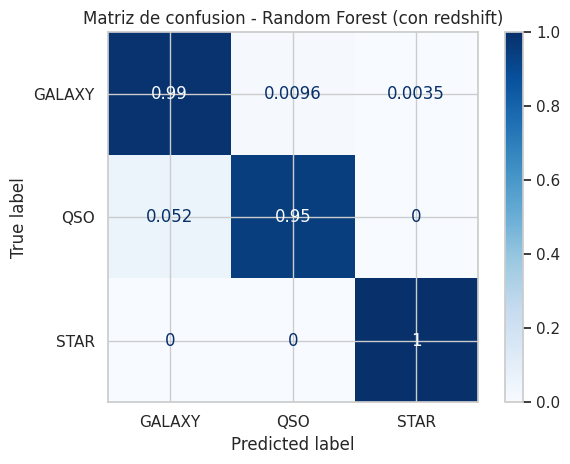

=== Random Forest - sin redshift ===
Accuracy : 0.9103
F1 macro : 0.8686

              precision    recall  f1-score   support

      GALAXY       0.96      0.95      0.95     11507
         QSO       0.76      0.78      0.77      2384
        STAR       0.88      0.88      0.88      6091

    accuracy                           0.91     19982
   macro avg       0.87      0.87      0.87     19982
weighted avg       0.91      0.91      0.91     19982



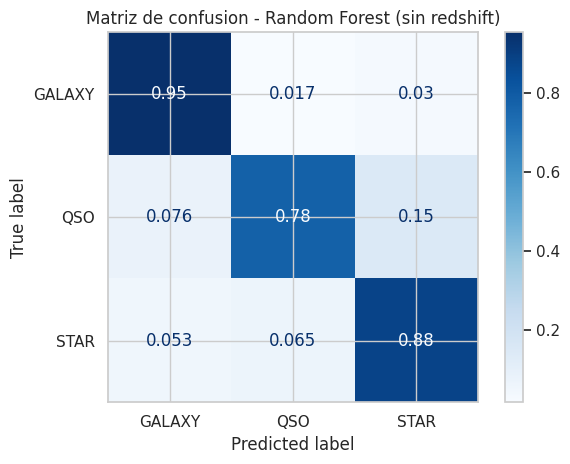

In [ ]:
rf_full = grid_rf_full.best_estimator_
_ = evaluar_modelo(rf_full, X_test_scaled_full, y_test, "Random Forest", "con redshift")

rf_sr = grid_rf_sr.best_estimator_
_ = evaluar_modelo(rf_sr, X_test_scaled_sr, y_test, "Random Forest", "sin redshift")

### Importancia de atributos

El Random Forest ofrece dos formas de medir qué tan importante es cada variable. La primera,
`feature_importances_`, viene gratis del entrenamiento (mide cuánto reduce cada variable la impureza,
promediado sobre todos los árboles), pero está sesgada a favor de variables con muchos valores
distintos. La segunda, la importancia por permutación, es más confiable: mide cuánto empeora el modelo
si se mezcla al azar una columna del test dejando todo lo demás igual, así que mide directamente el
efecto sobre la predicción y no sobre cómo se construyó el árbol. Se calcula sobre una submuestra del
test, por costo computacional (repite la predicción `n_repeats` veces por cada variable) — la misma
lógica de la submuestra usada para entrenar SVM.

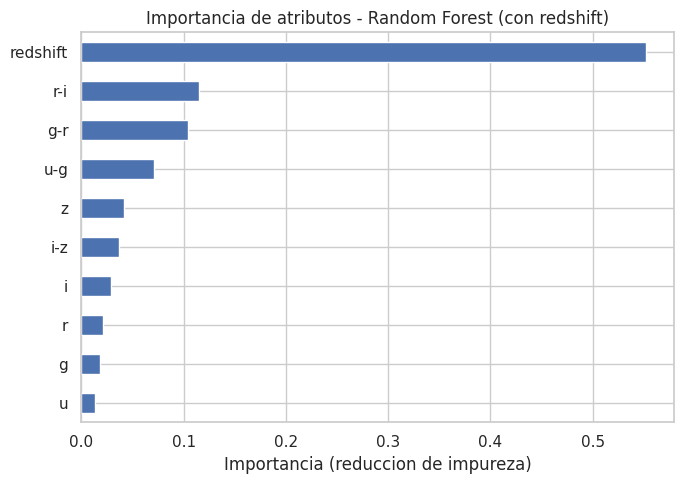

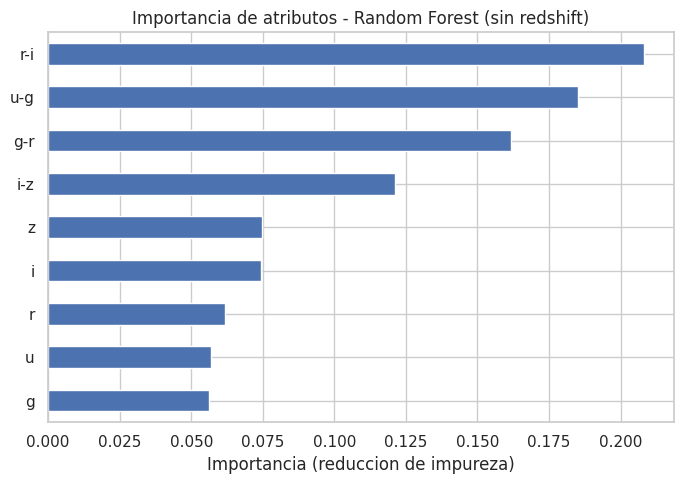

Con redshift:
redshift    0.5519
r-i         0.1146
g-r         0.1038
u-g         0.0711
z           0.0412
i-z         0.0363
i           0.0289
r           0.0213
g           0.0178
u           0.0131
dtype: float64

Sin redshift:
r-i    0.2082
u-g    0.1849
g-r    0.1616
i-z    0.1213
z      0.0747
i      0.0745
r      0.0617
u      0.0570
g      0.0561
dtype: float64


In [ ]:
def graficar_importancias(modelo, nombres, titulo):
    importancias = pd.Series(modelo.feature_importances_, index=nombres).sort_values()

    fig, ax = plt.subplots(figsize=(7, 5))
    importancias.plot.barh(ax=ax)
    ax.set_title(titulo)
    ax.set_xlabel("Importancia (reduccion de impureza)")
    plt.tight_layout()
    plt.show()

    return importancias.sort_values(ascending=False)


imp_full = graficar_importancias(
    rf_full, FEATURES,
    "Importancia de atributos - Random Forest (con redshift)"
)
imp_sr = graficar_importancias(
    rf_sr, FEATURES_SIN_REDSHIFT,
    "Importancia de atributos - Random Forest (sin redshift)"
)

print("Con redshift:")
print(imp_full.round(4))
print()
print("Sin redshift:")
print(imp_sr.round(4))

In [ ]:
from sklearn.inspection import permutation_importance

N_TEST_PERMUTACION = 5000

rng = np.random.RandomState(SEMILLA)
idx_muestra = rng.choice(len(X_test_scaled_sr), size=N_TEST_PERMUTACION, replace=False)

X_test_muestra_sr = X_test_scaled_sr.iloc[idx_muestra]
y_test_muestra = y_test[idx_muestra]

perm_sr = permutation_importance(
    rf_sr,
    X_test_muestra_sr,
    y_test_muestra,
    n_repeats=10,
    random_state=SEMILLA,
    scoring="f1_macro",
    n_jobs=-1
)

importancia_permutacion = pd.Series(
    perm_sr.importances_mean,
    index=FEATURES_SIN_REDSHIFT
).sort_values(ascending=False)

print("Importancia por permutacion (caida de f1_macro), sin redshift:")
print(importancia_permutacion.round(4))

Importancia por permutacion (caida de f1_macro), sin redshift:
r-i    0.3120
u-g    0.1795
i-z    0.1435
g-r    0.1427
z      0.0122
u      0.0102
r      0.0087
g      0.0077
i      0.0063
dtype: float64


Las dos medidas coinciden en el primer puesto: `r-i` es la variable más importante sin `redshift`,
tanto por impureza (0.208) como por permutación (0.312) — y es la misma variable que aparece en la raíz
del árbol de decisión. También coinciden bastante en el orden del resto: `u-g` y `g-r` ocupan el segundo
y tercer lugar en ambas medidas (aunque permutación pondera más `i-z` que `g-r`, al revés que
impureza). Las bandas individuales (`u`, `g`, `r`, `i`, `z`) quedan última en ambos rankings, muy por
debajo de los colores — confirma lo que sugería el análisis de correlación del EDA: los colores
aportan más información nueva que las bandas de las que se derivan.

Con `redshift`, esa variable domina ampliamente sobre el resto (0.552 de importancia, más que la suma de
las tres siguientes juntas), y es justo lo que cierra la pregunta de investigación: la mayor parte de lo
que separa a GALAXY, QSO y STAR es directamente el corrimiento al rojo. Sin `redshift` el problema sigue
siendo resoluble (F1 macro 0.87 con Random Forest, contra 0.98 con redshift, según la tabla de
resultados), pero apoyado casi por completo en un solo color (`r-i`) en vez de repartirse entre varias
variables — un modelo sin `redshift` es más frágil que uno que reparte la decisión entre muchos
atributos, porque depende fuerte de una sola medición.

### Comparación de todos los modelos

In [ ]:
tabla_resultados = pd.DataFrame(resultados_modelos)
print(tabla_resultados.round(4).to_string(index=False))

       Modelo     Variante  Accuracy  F1 macro
          KNN con redshift    0.9559    0.9460
          KNN sin redshift    0.8793    0.8285
          SVM con redshift    0.9665    0.9576
          SVM sin redshift    0.8818    0.8343
        Arbol con redshift    0.9784    0.9656
        Arbol sin redshift    0.8676    0.8150
Random Forest con redshift    0.9863    0.9786
Random Forest sin redshift    0.9103    0.8686


## Lo que sigue

Esta notebook se construye por partes, a medida que avanza la cursada. El estado de cada bloque:

| Bloque | Depende de | Estado |
|---|---|:--:|
| Fuente de los datos y propuesta de investigación | — | ✅ |
| Carga y estado del conjunto de datos | — | ✅ |
| Análisis exploratorio: distribuciones, colores fotométricos, correlaciones | clase 1 | ✅ |
| Preprocesamiento: valores nulos, duplicados | clase 1 | ✅ |
| Preprocesamiento: balanceo, partición estratificada, escalado | clase 1 | ✅ |
| **KNN** como primera línea de base | clase 2 | ✅ |
| **SVM** | clase 3 | ✅ |
| **Árboles de decisión** | clase 4 | ✅ |
| **Ensambles** e importancia de atributos | clase 5 | ✅ |
| **Agrupamiento**: ¿recupera las tres clases? | clase 6 | ⬜ |
| **Calibración** sobre el corte binario quásar contra el resto | clase 7 | ⬜ |
| Requisito 4: comparación y justificación del algoritmo elegido | clases 2 a 5 | ⬜ |
| Requisito 7: reflexión y propuestas de mejora | todas | ⬜ |